# libnreria pillow

In [1]:
!pip install pillow
!pip install ipywidgets


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from PIL import Image # objeto principal de la lubreria pillow(IMAGE) se puede cargar poniendo el path de una imagen.
import numpy as np
import urllib.request

# Download an image
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/sample.png'
urllib.request.urlretrieve(url, "sample.png")

# Load an image
image = Image.open("sample.png")
# este objetivo tienes distintas caracteristicas

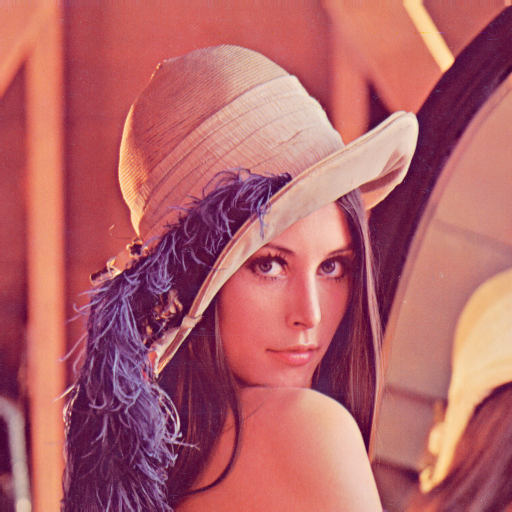

In [3]:
# una de las caracteristicas es que cuando llamamos a este objeto hace un plot de la imagen:
image

In [4]:
# atributos principales:
print('format:', image.format)  # Output might be 'JPEG', 'PNG', etc.
print('size:', image.size)  # Output might be (width, height) like (640, 480)
print('mode:', image.mode)  # Output might be 'RGB', 'L', etc.
print('info:', image.info)  # Output might be a dictionary with metadata

format: PNG
size: (512, 512)
mode: RGB
info: {'srgb': 0}


In [5]:
# este objeto imagen lo podemos pasar a modo array para tratarlo como array:
# Convert the image to a NumPy array
image_array = np.array(image)

# Display the shape of the array
print(image_array.shape)  # The shape will be in the form of (height, width, channels)

(512, 512, 3)


In [6]:
# sia ccedemos a algunos elementos del array, vemos que son nuemros entre 0 y 255:
image_array[:3,:3,:]

array([[[226, 137, 125],
        [226, 137, 125],
        [223, 137, 133]],

       [[226, 137, 125],
        [226, 137, 125],
        [223, 137, 133]],

       [[226, 137, 125],
        [226, 137, 125],
        [223, 137, 133]]], dtype=uint8)

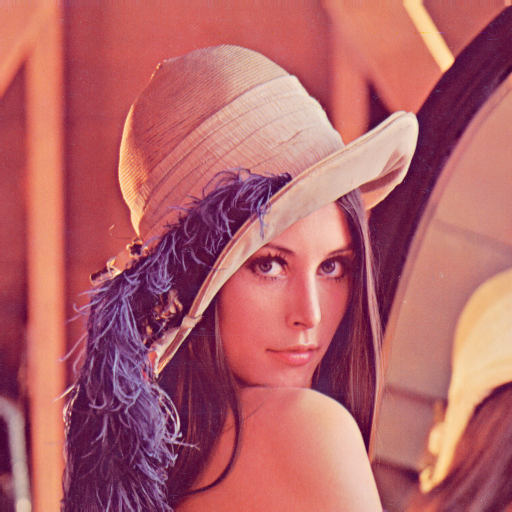

In [7]:
# para volver a crear la imagen a partir del array:
# Convert the NumPy array back to a Pillow Image object
new_image = Image.fromarray(image_array)
new_image

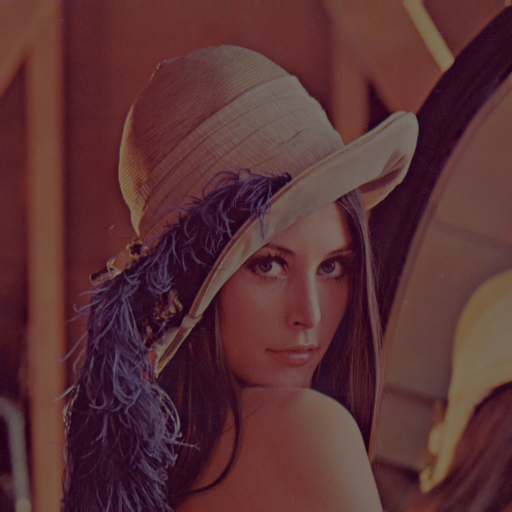

In [8]:
# vamos a jugar un poco:
mi_array = np.asarray(image_array) // 2
my_image = Image.fromarray(mi_array.astype(np.uint8))
my_image #como vbemos reduce brillo pero no cambia el color ayq ue es el mismo siempre

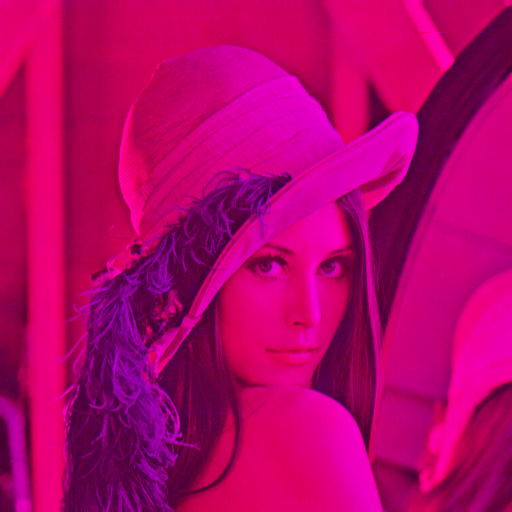

In [9]:
mi_array = np.asarray(image_array).copy()
mi_array[:, :, 1] = 0
my_image = Image.fromarray(mi_array.astype(np.uint8))
my_image # aqui como hemos quitado una capa, cambia drasticamente de color
# q diver!

In [10]:
image.show() # para hacer display en la app de fotos

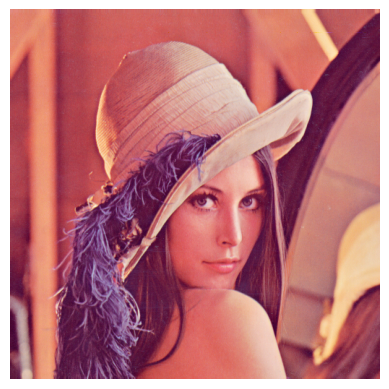

In [11]:
# tmb se puede ahcer con matplotlib:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(np.array(image))
plt.axis('off')  # Turn off axis numbers and labels
plt.show()

In [12]:
# una de las operaciones mas basicas es diviidir las imagenes en r, g b:
print(image.mode)  # Output: 'RGB'
r, g, b = image.split() # asi es como dividimos en los distintos colores

RGB


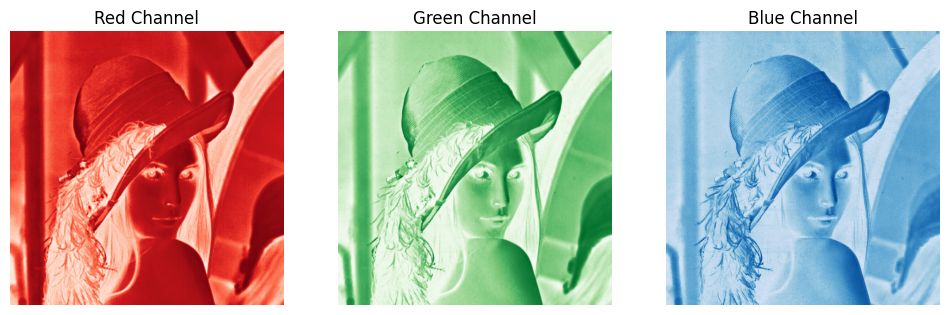

In [13]:
# vemos cada uno de los colores:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(r, cmap='Reds')
axes[0].set_title('Red Channel')
axes[0].axis('off')

axes[1].imshow(g, cmap='Greens')
axes[1].set_title('Green Channel')
axes[1].axis('off')

axes[2].imshow(b, cmap='Blues')
axes[2].set_title('Blue Channel')
axes[2].axis('off')

plt.show()

In [14]:
# otra de las mas tipicas es pasar a escala de grises:
gray_image = image.convert('L') # esta es para escala de grises. estamos convirtiendolo de rgd a grises
print(gray_image.mode)  # Output: 'L'

L


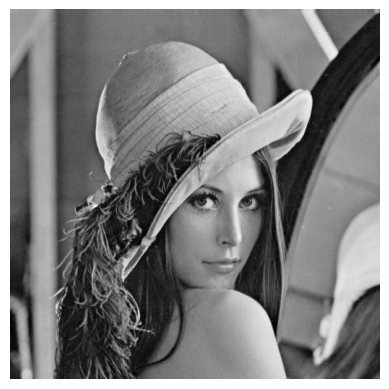

In [15]:
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

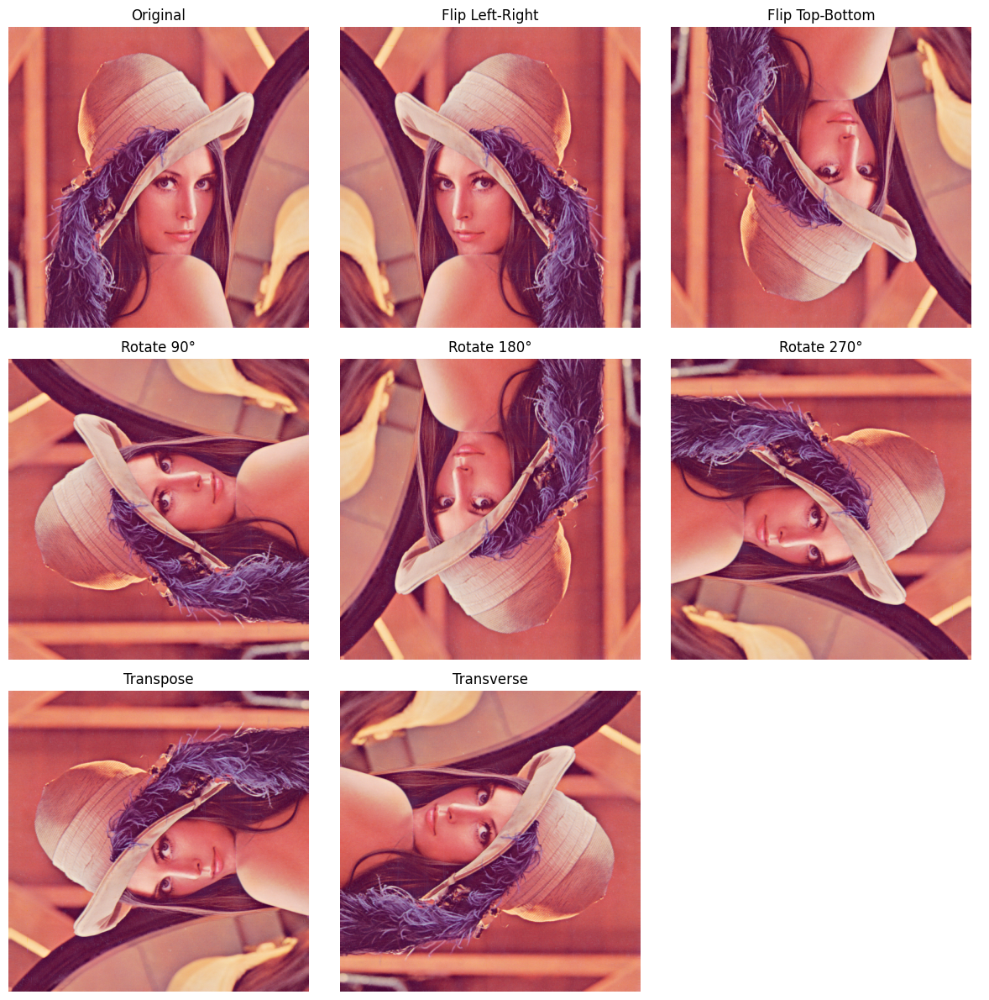

In [16]:
# manipulacion bhasica de imagene: hacer rotaciones, truncar,...

# Apply different transpositions and rotations
flipped_lr = image.transpose(Image.FLIP_LEFT_RIGHT)
flipped_tb = image.transpose(Image.FLIP_TOP_BOTTOM)
rotated_90 = image.transpose(Image.ROTATE_90)
rotated_180 = image.transpose(Image.ROTATE_180)
rotated_270 = image.transpose(Image.ROTATE_270)
transposed = image.transpose(Image.TRANSPOSE)
transversed = image.transpose(Image.TRANSVERSE)

# Plotting all the images with titles
fig, axs = plt.subplots(3, 3, figsize=(12, 12))

# Original Image
axs[0, 0].imshow(image)
axs[0, 0].set_title("Original")
axs[0, 0].axis('off')

# Flipped Left-Right
axs[0, 1].imshow(flipped_lr)
axs[0, 1].set_title("Flip Left-Right")
axs[0, 1].axis('off')

# Flipped Top-Bottom
axs[0, 2].imshow(flipped_tb)
axs[0, 2].set_title("Flip Top-Bottom")
axs[0, 2].axis('off')

# Rotated 90°
axs[1, 0].imshow(rotated_90)
axs[1, 0].set_title("Rotate 90°")
axs[1, 0].axis('off')

# Rotated 180°
axs[1, 1].imshow(rotated_180)
axs[1, 1].set_title("Rotate 180°")
axs[1, 1].axis('off')

# Rotated 270°
axs[1, 2].imshow(rotated_270)
axs[1, 2].set_title("Rotate 270°")
axs[1, 2].axis('off')

# Transpose
axs[2, 0].imshow(transposed)
axs[2, 0].set_title("Transpose")
axs[2, 0].axis('off')

# Transverse
axs[2, 1].imshow(transversed)
axs[2, 1].set_title("Transverse")
axs[2, 1].axis('off')

# Empty subplot (for layout purposes)
axs[2, 2].axis('off')

plt.tight_layout()
plt.show()


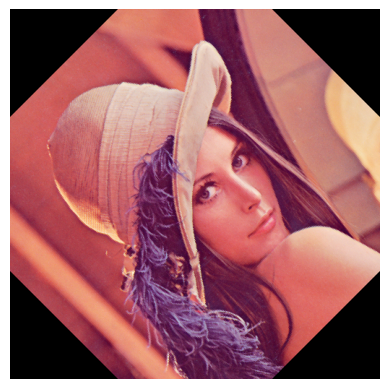

In [17]:
# luego tmb se puede rotar uin numero de grados especifico:
rotated_image = image.rotate(45)
plt.imshow(rotated_image)
plt.axis('off')
plt.show()

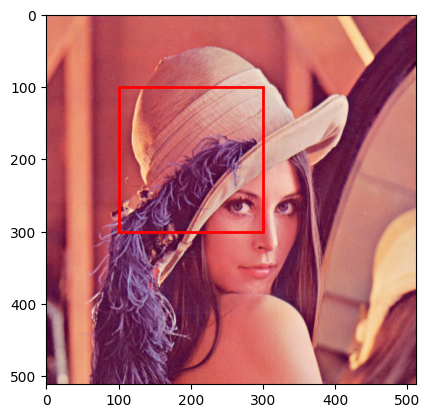

In [18]:
# crop box: coger una parte de la imagen en especifico:
import matplotlib.patches as patches

crop_box = (100, 100, 300, 300)

# Create a Rectangle patch
rect = patches.Rectangle((crop_box[0], crop_box[1]), crop_box[2] - crop_box[0], crop_box[3] - crop_box[1], linewidth=2, edgecolor='r', facecolor='none')

# Plot the original image and the rectangle
fig, ax = plt.subplots()
ax.imshow(image)
ax.add_patch(rect)
plt.show() # estas son las coordenadas. si realmente eso es lo q queremos seleccionar, lo cogemos:

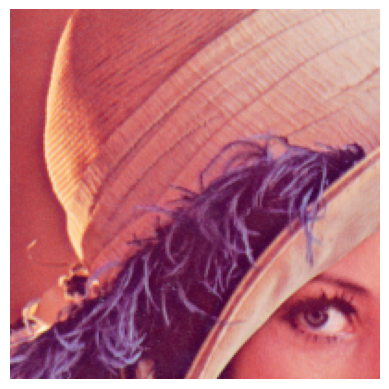

In [19]:
# Define the box to crop
cropped_image = image.crop(crop_box)

# Display the cropped image
plt.imshow(cropped_image)
plt.axis('off')
plt.show()

In [20]:
print(image.size, cropped_image.size)

(512, 512) (200, 200)


In [21]:
# otra de las caractristicas princpales es poder cambiar el tamaño de las imagenes:
resized_image = image.resize((200, 200), Image.LANCZOS)
print(image.size, resized_image.size)

(512, 512) (200, 200)


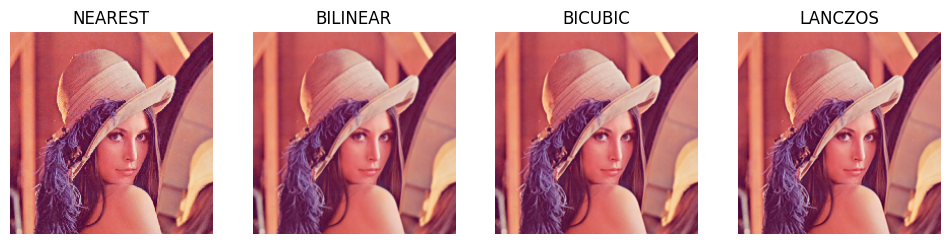

In [22]:
# Resizing with different methods
nearest = image.resize((200, 200), Image.NEAREST)
bilinear = image.resize((200, 200), Image.BILINEAR)
bicubic = image.resize((200, 200), Image.BICUBIC)
lanczos = image.resize((200, 200), Image.LANCZOS)

# Plotting the images
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(nearest)
axes[0].set_title("NEAREST")
axes[0].axis('off')

axes[1].imshow(bilinear)
axes[1].set_title("BILINEAR")
axes[1].axis('off')

axes[2].imshow(bicubic)
axes[2].set_title("BICUBIC")
axes[2].axis('off')

axes[3].imshow(lanczos)
axes[3].set_title("LANCZOS")
axes[3].axis('off')

plt.show()
# segun un algoritmo u otro sirven para que tengas mas calidad, mas rapidez,... depende de lo que se queire

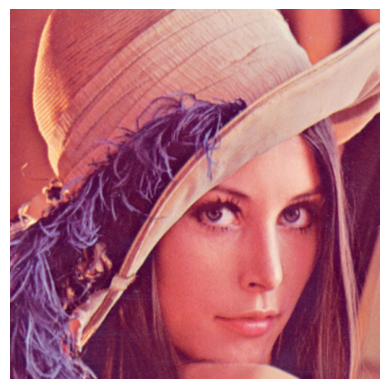

In [23]:
# devolver el tamaño original una imagen recortada:
original_size = image.size

# Crop the image
crop_box = (100, 100, 400, 400)
cropped_image = image.crop(crop_box)

# Resize the cropped image to the original size
resized_cropped_image = cropped_image.resize(original_size, Image.LANCZOS)

plt.imshow(resized_cropped_image)
plt.axis('off')
plt.show()

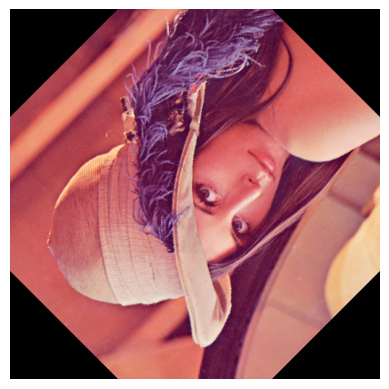

In [24]:
## ejercicios
#1: Rotate the image 45º and flip top to bottom
rotated_image = image.rotate(45)
flipped_tb = rotated_image.transpose(Image.FLIP_TOP_BOTTOM)
image_1 = flipped_tb


plt.imshow(image_1)
plt.axis('off')
plt.show()

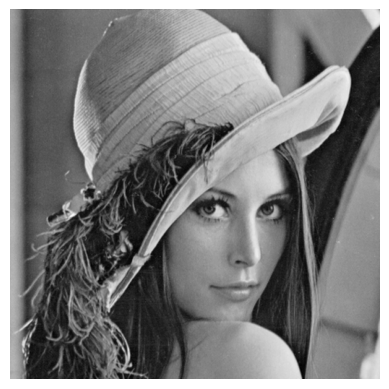

In [25]:
# 2: Crop the image to a crop box of `(50, 50, 450, 450)`, resize in to a `256 x 256 x 3` using any method, image and convert it to gray scale 
crop_box = (50, 50, 450, 450)

cropped_image = image.crop(crop_box)
original_size = image.size
resized_cropped_image = cropped_image.resize(original_size, Image.LANCZOS)

gray_image = resized_cropped_image.convert('L')

image_2 = gray_image


plt.imshow(image_2, cmap='gray')
plt.axis('off')
plt.show()

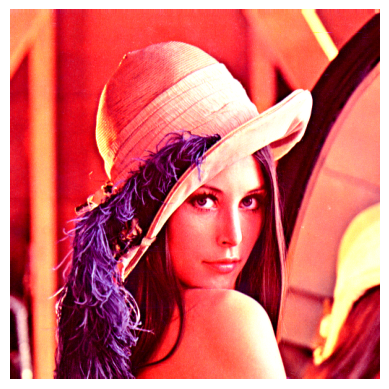

In [26]:
# ortras utilizdades para mejorar la calidad de los pixeles y de las imagens. contraste por ejempoolo. cuanto mayor es el numero, mas claro sale y vicebersa. el ajuste del brillos es multiplicar el numero por un factor
# contraste:
from PIL import ImageEnhance


# Enhance contrast
enhancer = ImageEnhance.Contrast(image)
contrast_image = enhancer.enhance(2)  # Increase contrast

plt.imshow(contrast_image)
plt.axis('off')
plt.show()

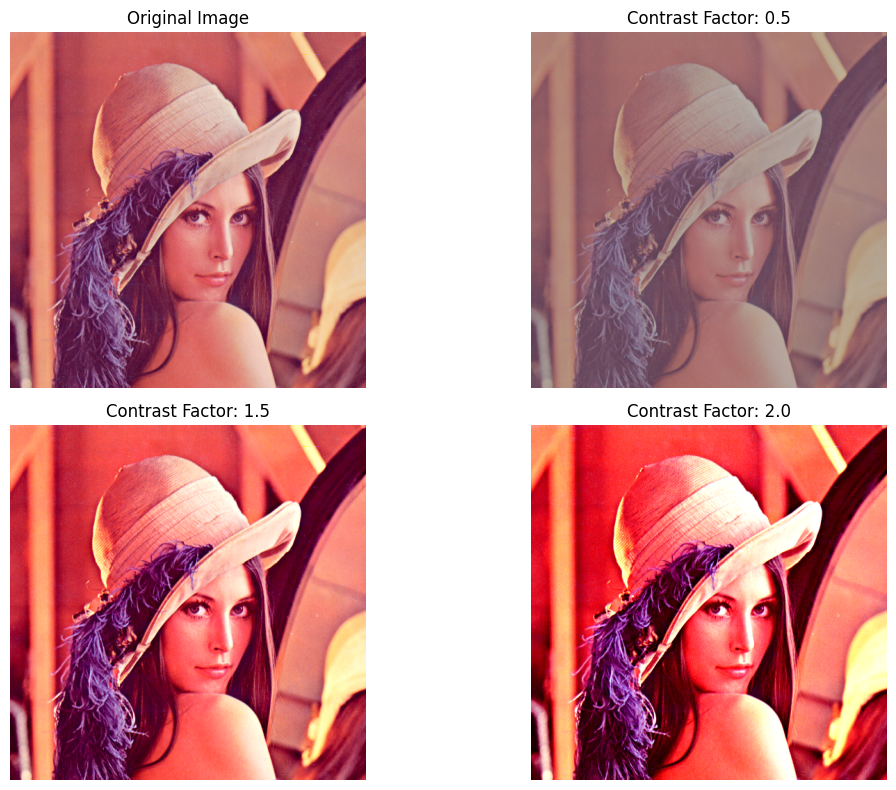

In [27]:
contrast_factors = [0.5, 1.5, 2.0]
contrast_images = [ImageEnhance.Contrast(image).enhance(factor) for factor in contrast_factors]

# Plot original and contrast-enhanced images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

for i, contrast_image in enumerate(contrast_images, start=2):
    plt.subplot(2, 2, i)
    plt.imshow(contrast_image)
    plt.title(f'Contrast Factor: {contrast_factors[i-2]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

# aqui por ejemplo modificando el brillo de las imagenes

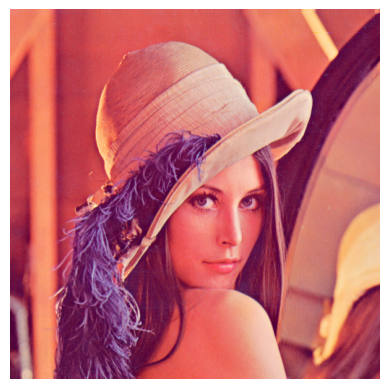

In [28]:
enhancer = ImageEnhance.Color(image)
color_enhanced_image = enhancer.enhance(1.2)  # Enhance color

plt.imshow(color_enhanced_image)
plt.axis('off')
plt.show()

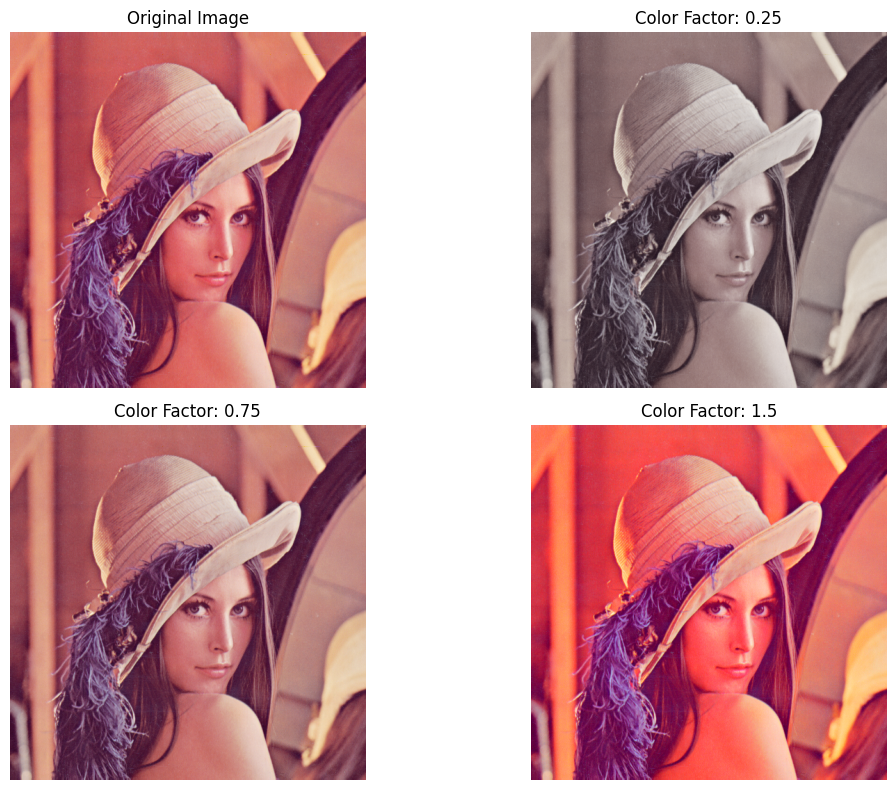

In [29]:
color_factors = [0.25, 0.75, 1.5]
color_images = [ImageEnhance.Color(image).enhance(factor) for factor in color_factors]

# Plot original and contrast-enhanced images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

for i, color_image in enumerate(color_images, start=2):
    plt.subplot(2, 2, i)
    plt.imshow(color_image)
    plt.title(f'Color Factor: {color_factors[i-2]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

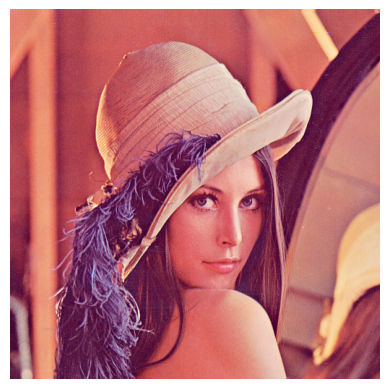

In [30]:
# tambien se puede hacer lo mismo con el sharpness (realzar mas o menos lo que hay dentro del borde de una imagen)
enhancer = ImageEnhance.Sharpness(image)
sharp_image = enhancer.enhance(2)  # Sharpen the image

plt.imshow(sharp_image)
plt.axis('off')
plt.show()

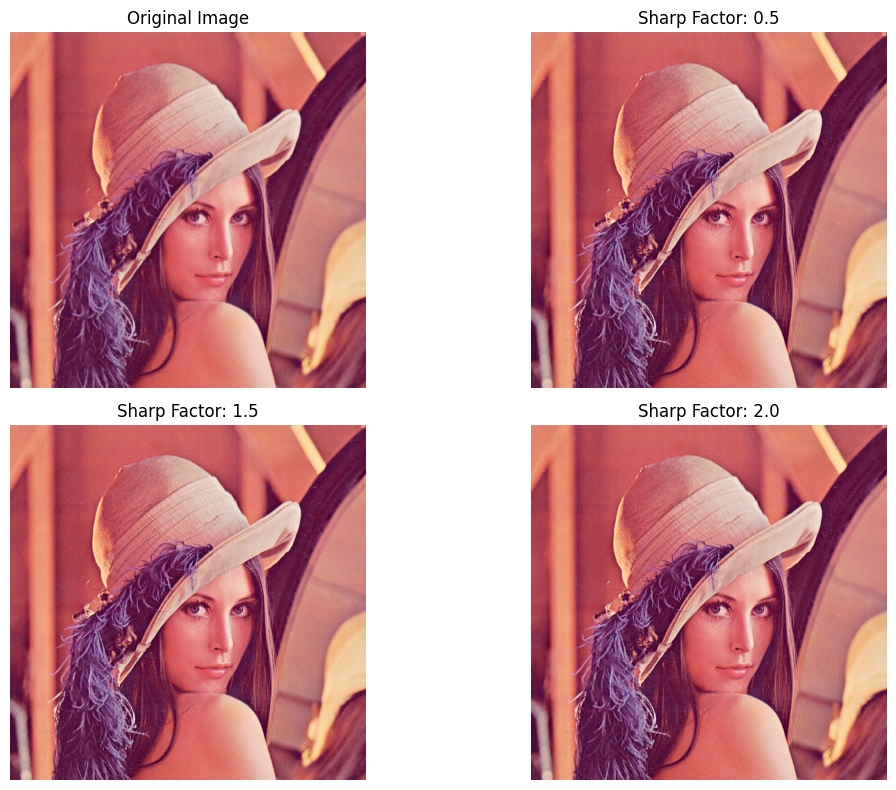

In [31]:
sharp_factors = [0.5, 1.5, 2.0]
sharp_images = [ImageEnhance.Sharpness(image).enhance(factor) for factor in sharp_factors]

# Plot original and contrast-enhanced images
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

for i, bright_image in enumerate(sharp_images, start=2):
    plt.subplot(2, 2, i)
    plt.imshow(sharp_image)
    plt.title(f'Sharp Factor: {sharp_factors[i-2]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# otras veces cuando estamos haciendo un problema por ejemplo aumentar la calidad de unos documentos, tenemos que estudair el tipo de imagen o ir probando cual nos podria ir bien:
# cone ste metodo por ejempplo, se puede controlar a mano para ir probando que nos viene bien:
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt

def interactive_enhancements(brightness, contrast, color, sharpness):
    enhancer = ImageEnhance.Brightness(image)
    enhanced_image = enhancer.enhance(brightness)

    enhancer = ImageEnhance.Contrast(enhanced_image)
    enhanced_image = enhancer.enhance(contrast)

    enhancer = ImageEnhance.Color(enhanced_image)
    enhanced_image = enhancer.enhance(color)

    enhancer = ImageEnhance.Sharpness(enhanced_image)
    enhanced_image = enhancer.enhance(sharpness)

    plt.imshow(enhanced_image)
    plt.axis('off')
    plt.show()

brightness_slider = widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=1.0, description='Brightness:')
contrast_slider = widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=1.0, description='Contrast:')
color_slider = widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=1.0, description='Color:')
sharpness_slider = widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=1.0, description='Sharpness:')

widgets.interactive(interactive_enhancements, brightness=brightness_slider, contrast=contrast_slider, color=color_slider, sharpness=sharpness_slider)

interactive(children=(FloatSlider(value=1.0, description='Brightness:', max=2.0, min=0.1), FloatSlider(value=1…